# Data-quality experiments

## Summary
Controlled experiments on real source images measure preprocessing effects. These are not model benchmarks or evidence of generalisation.

In [1]:
from pathlib import Path
import os, sys, json, importlib.util, subprocess
try:
    IN_COLAB = importlib.util.find_spec('google.colab') is not None
except ModuleNotFoundError:
    IN_COLAB = False
roots = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next((p for p in roots if (p / 'configs/datasets.yaml').exists()), None)
if PROJECT_ROOT is None and IN_COLAB:
    PROJECT_ROOT = Path('/content/TerraWatch')
    if not (PROJECT_ROOT / '.git').exists():
        subprocess.run(['git','clone','--branch','data-preparation',
            'https://github.com/shoaib2000857/Group-7-DS-and-AI-Lab-Project.git',str(PROJECT_ROOT)],check=True)
    subprocess.run([sys.executable,'-m','pip','install','-q','-r',str(PROJECT_ROOT/'requirements-data.txt')],check=True)
if PROJECT_ROOT is None:
    raise RuntimeError('Clone the project first, then open this notebook in its notebooks folder. See notebooks/README.md.')
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path: sys.path.insert(0, str(PROJECT_ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.data.catalog import load_catalog
from src.data.preprocess import read_jsonl
AUDIT_DIR = PROJECT_ROOT / 'outputs/data'
PROCESSED_DIR = PROJECT_ROOT / 'data/processed'
DATA_ROOT = os.getenv('TERRAWATCH_DATA_ROOT')  # e.g. /content/drive/MyDrive/TerraWatch_Extracted
CONFIG = PROJECT_ROOT / 'configs/datasets.yaml'


## Context and methods
Use one fixed real pair for controlled comparisons. Photometric perturbations are synthetic stress cases and are labelled as such. Mask components are not treated as object counts.

## Data

In [2]:
from src.data.dataset import PairDataset, paired_augmentation
ds=PairDataset(PROCESSED_DIR/'train.jsonl',PROCESSED_DIR)
profiles={r['pair_id']:r for r in read_jsonl(AUDIT_DIR/'profiles.jsonl')}
idx=next(i for i,r in enumerate(ds.rows) if r['dataset']=='levir_mci' and 0<profiles[r['pair_id']].get('changed_fraction',0)<.01)
sample=ds[idx]; a,b=sample['t1'],sample['t2'];mask=sample['targets']['target']
print('Pair:',sample['pair_id'])

Pair: levir_mci/train/train_000021


## Results
### Resize sensitivity

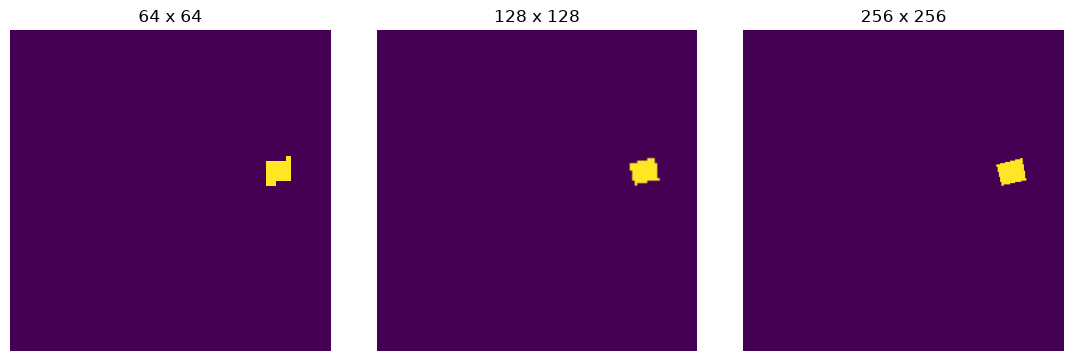

,size,changed_fraction,classes
0,64,0.005615,"[0, 2]"
1,128,0.005493,"[0, 2]"
2,256,0.005524,"[0, 2]"


In [3]:
from PIL import Image
rows=[]
fig,axes=plt.subplots(1,3,figsize=(11,3.5),layout='constrained')
for ax,size in zip(axes,[64,128,256]):
    m=np.array(Image.fromarray(mask.astype(np.uint8)).resize((size,size),Image.Resampling.NEAREST))
    rows.append({'size':size,'changed_fraction':float((m>0).mean()),'classes':str(np.unique(m).tolist())})
    ax.imshow(m,vmin=0,vmax=2);ax.set_title(f'{size} x {size}');ax.axis('off')
plt.show();display(pd.DataFrame(rows))

### Brightness perturbations can change pixel differences without construction

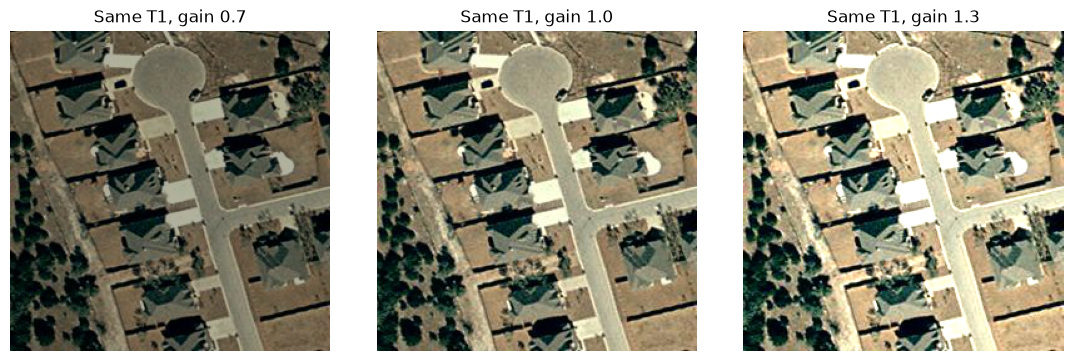

,synthetic_brightness_gain,mae_against_same_source
0,0.7,34.531275
1,1.0,0.000000
2,1.3,30.857559


In [4]:
rows=[];fig,axes=plt.subplots(1,3,figsize=(11,3.5),layout='constrained')
for ax,gain in zip(axes,[.7,1.,1.3]):
    altered=np.clip(a.astype(float)*gain,0,255).astype(np.uint8)
    rows.append({'synthetic_brightness_gain':gain,'mae_against_same_source':float(np.abs(a.astype(float)-altered).mean())})
    ax.imshow(altered);ax.set_title(f'Same T1, gain {gain}');ax.axis('off')
plt.show();display(pd.DataFrame(rows))

### Paired geometry and caption safeguards

In [5]:
ta,tb,tm=paired_augmentation(a,b,mask,'flip_horizontal',has_caption=False)
assert np.array_equal(tm,np.flip(mask,axis=1))
try:
    paired_augmentation(a,b,mask,'flip_horizontal',has_caption=True)
except ValueError as exc:
    print('Caption safeguard:',exc)
print('Label histogram preserved:',np.array_equal(np.bincount(mask.ravel()),np.bincount(tm.ravel())))
ds.close()

Caption safeguard: Geometric augmentation requires separately transformed caption/region references
Label histogram preserved: True


## Takeaways
Resolution can remove small regions; brightness differences alone are not structural-change labels. Geometric transforms need matching target transforms, and spatial captions require their own verified transformation rules. These experiments establish preprocessing behaviour only.